# 5.1 · 组合构建基础：从预测分数到持仓权重

> 模型输出的是每个股票的预测分数（预期收益）。**组合构建（portfolio construction）要回答：每只股票到底买多少、权重多少。**
> 本节先掌握最简单、最常用的权重规则，理解权重的基本约束；下一节再进入均值-方差优化。

## 一、组合构建在流程中的位置

因子/模型 → **预测分数** → **组合构建（打分→权重）** → 下单执行 → 持有。

组合构建的目标：
- 把"看好程度"转化为"持仓权重"；
- 在追求收益的同时，**控制风险（分散、限单票、控行业）和成本（换手）**。

> 同样的预测信号，不同的组合构建方法，最终收益可能差别很大。

## 二、最简单的权重规则

| 规则 | 做法 | 特点 |
|---|---|---|
| **等权** | 所有候选股票相同权重 | 最简单、最分散 |
| **Top-N 等权** | 只买分数最高的 N 只，等权 | 集中、常用 |
| **打分加权** | 分数非负化后按比例分配 | 越看好权重越大 |
| **多空** | 做多 Top N、做空 Bottom N | 市场中性 |

权重必须满足：满仓（多头权重和=1）、非负（不做空时）、单票不超限。

## 三、单日演示（代码在 portfolio_lab.weighting）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.library import build_factors
from portfolio_lab.weighting import (equal_weight, topn_equal, score_weight,
                                     long_short_weights, portfolio_return)
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
facs = build_factors(close, F['$volume'].unstack('instrument'),
                     F['$mkt_cap_ard'].unstack('instrument'),
                     F['$pe_ttm'].unstack('instrument'),
                     F['$pb_lf'].unstack('instrument'))
scores = facs['SMB 小市值'].iloc[-2]; ret_next = close.pct_change().iloc[-1]
for name, w in [('等权', equal_weight(scores)),
                ('Top30', topn_equal(scores, 30)),
                ('打分加权', score_weight(scores)),
                ('多空', long_short_weights(scores, 30))]:
    print('%-7s 持仓 %d 只  权重和 %.2f  次日收益 %.4f' %
          (name, (w != 0).sum(), w.sum(), portfolio_return(w, ret_next)))

[19728:MainThread](2026-10-30 01:32:21,492) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[19728:MainThread](2026-10-30 01:32:22,956) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[19728:MainThread](2026-10-30 01:32:22,958) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


等权      持仓 300 只  权重和 1.00  次日收益 -0.0097
Top30   持仓 30 只  权重和 1.00  次日收益 -0.0160
打分加权    持仓 299 只  权重和 1.00  次日收益 -0.0110
多空      持仓 60 只  权重和 -0.00  次日收益 -0.0213


## 四、长期对比：不同规则的组合表现（每日再平衡，暂不计成本）

      等权(300)  Top30小市值  Top100小市值
年化收益    0.140     0.572      0.292
年化波动    0.176     0.264      0.215
夏普      0.793     2.165      1.353


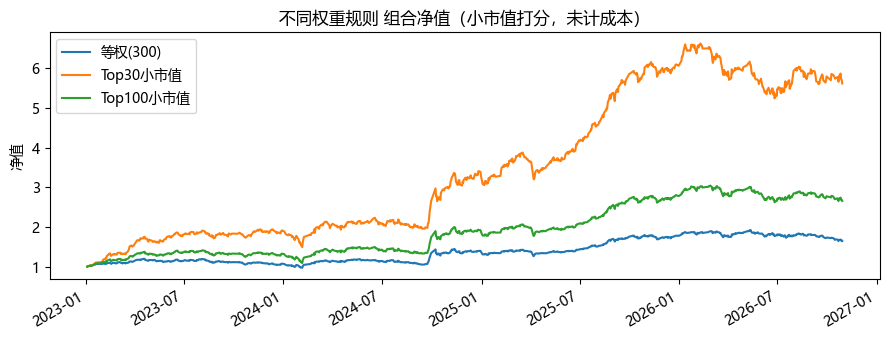

In [2]:
def run_rule(scores_panel, ret_panel, weight_fn, start='2023-01-01'):
    rets = {}
    idx = scores_panel.loc[start:].index
    for dt in idx[:-1]:
        i = scores_panel.index.get_loc(dt)
        w = weight_fn(scores_panel.iloc[i])
        r = ret_panel.iloc[i+1]
        rets[ret_panel.index[i+1]] = portfolio_return(w, r)
    return pd.Series(rets)

ret_panel = close.pct_change()
sp = facs['SMB 小市值']
port = {
    '等权(300)': run_rule(sp, ret_panel, equal_weight),
    'Top30小市值': run_rule(sp, ret_panel, lambda s: topn_equal(s, 30)),
    'Top100小市值': run_rule(sp, ret_panel, lambda s: topn_equal(s, 100)),
}
def perf(r):
    ann = (1+r).prod()**(242/len(r))-1; sd = r.std()*np.sqrt(242)
    return pd.Series({'年化收益': ann, '年化波动': sd, '夏普': ann/sd})
summary = pd.DataFrame({k: perf(v) for k, v in port.items()})
print(summary.round(3))

pd.DataFrame({k: (1+v).cumprod() for k, v in port.items()}).plot(figsize=(9,3.5))
plt.title('不同权重规则 组合净值（小市值打分，未计成本）'); plt.ylabel('净值')
plt.tight_layout(); plt.show()

## 五、解读

- 越集中（Top30）在小市值风格上暴露越极端，风格顺风时收益高、逆风时回撤大；
- 等权/Top100 更分散、更稳健；
- 这里**没有考虑交易成本和换手**（每日再平衡换手很高），真实收益会明显下降（模块 6 会扣成本）。

> 简单规则透明、稳健，但无法主动权衡"收益 vs 风险"。下一节用均值-方差优化，在给定风险下追求最大收益。

## 六、小结与面试要点

- 组合构建把预测分数转化为权重：等权、Top-N、打分加权、多空。
- 权重基本约束：满仓、非负、单票上限；集中=高收益高风险，分散=稳健。
- 简单规则是必做基准；评估组合必须考虑成本和换手（模块 6）。

**面试高频：**
- 常见的选股组合权重方法？（答：等权、Top-N 等权、打分加权、优化）
- Top-N 等权相比全市场等权的利弊？（答：信号更集中、可能更高收益，但风险和回撤更大）
- 为什么回测要考虑换手？（答：每日再平衡交易成本高，会侵蚀收益）

## 动手练习
1. 改变 Top-N 的 N，对比夏普；
2. 用模型预测（而非单因子）打分，构建 Top50；
3. 思考：多空组合为什么能"市场中性"？

---
下一节 **5.2 均值-方差模型：Markowitz、有效前沿、风险厌恶**。